1.1 How often does pole position turn into a win, by driver and by decade?



In [29]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("/home/aris/projects/F1-Analysis/data/processed/results_joined.csv", low_memory=False)

In [30]:
#Keep only the pole position drivers and then length of the amount of those drivers

poles = df[df["pole"]]
len(poles)

1179

In [31]:
# Share of pole sitters who went on to win, per decade
by_decade = poles.groupby("decade")["won"].mean() * 100
by_decade.round(1)

#Output takeaway is that in 1950 decade, 37.6% of pole starts ended in a win

decade
1950    37.6
1960    36.3
1970    36.8
1980    28.2
1990    42.6
2000    50.0
2010    50.5
2020    56.7
Name: won, dtype: float64

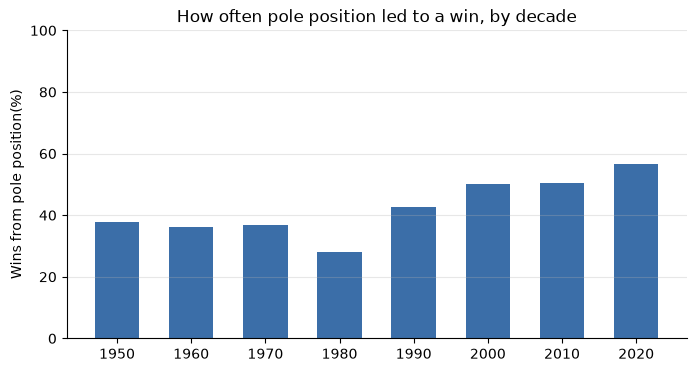

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decade.index.astype(str), by_decade.values, color="#3b6ea8", width=0.6)
ax.set_title("How often pole position led to a win, by decade")
ax.set_ylabel("Wins from pole position(%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

From the 1950s to the 1970s, about 36–38% of pole starts ended in a win.
The 1980s stand out at 28.2%, much lower than the decades around them.
After the 1980s, the win rate from pole rises every decade and peaks in the 2020s at 56.7%.

In [ ]:
# For each driver: how many poles, how many wins from pole, and the rate
by_driver = poles.groupby("driver").agg(poles=("won", "size"), wins=("won", "sum"))
by_driver["win_rate"] = (by_driver["wins"] / by_driver["poles"] * 100).round(1)

# Only drivers with at least 15 poles, best rate first
by_driver[by_driver["poles"] >= 15].sort_values("win_rate", ascending=False)

,poles,wins,win_rate
driver,,,
Max Verstappen,50,39,78.0
Fernando Alonso,22,14,63.6
Michael Schumacher,68,40,58.8
Lewis Hamilton,105,61,58.1
Alain Prost,33,18,54.5
Sebastian Vettel,57,31,54.4
Nigel Mansell,32,17,53.1
Lando Norris,19,10,52.6
Nico Rosberg,30,15,50.0


Among drivers with at least 15 poles, the five best at turning pole into a win are Max Verstappen, Fernando Alonso, Michael Schumacher, Lewis Hamilton and Alain Prost. Verstappen leads at 78.0%, 14.4 percentage points ahead of Alonso in second. Lewis Hamilton has the most pole starts of any driver, with 105.